# 07 · 딥러닝 이해와 비전 검사
### 실습으로 배우는 GMP AI — 강의 목차 ⑦ 딥러닝 이해와 비전 검사

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/07_Deep_Learning_Vision_Inspection.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① CNN 의 작동 원리(합성곱·풀링·전이학습) ② **정상 제품만으로 학습하는 외관 검사** ③ **결함 위치 히트맵**(설명가능성) ④ 지도학습 분류와 비교 ⑤ 검사 임계값과 **과검출/미검출** 비용 ⑥ 객체 검출(YOLO) 개념 ⑦ GMP 검증 고려사항 |
| **데이터** | **MVTec AD — 캡슐(capsule)** : 정상 219장 + 결함 5종(균열·인쇄불량·찍힘·긁힘·눌림) 실제 산업 검사 이미지 |
| **실행 환경** | CPU 가능(약 10분) · **GPU(T4) 권장** — [런타임] → [런타임 유형 변경] |

> **데이터 출처·라이선스**: MVTec Anomaly Detection Dataset (Bergmann et al., CVPR 2019) — **CC BY-NC-SA 4.0 (비영리)**.
> 교육·연구 목적으로만 사용하고, 논문 인용이 필요합니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, glob, os, time, tarfile, urllib.request
import warnings; warnings.filterwarnings("ignore")
import torch, torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ 준비 완료 — device:", device)

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료 — device: cpu


In [2]:
# 데이터 다운로드 (약 400MB, 1~2분)
URL = "https://huggingface.co/datasets/alexsu52/mvtec_capsule/resolve/main/capsule.tar.xz"
if not os.path.exists("capsule"):
    t = time.time(); urllib.request.urlretrieve(URL, "capsule.tar.xz")
    with tarfile.open("capsule.tar.xz") as f: f.extractall(".")
    print(f"다운로드·압축해제 완료 ({time.time()-t:.0f}초)")
train_paths = sorted(glob.glob("capsule/train/good/*.png"))
test_dirs = {os.path.basename(d): sorted(glob.glob(d + "/*.png")) for d in sorted(glob.glob("capsule/test/*"))}
print("학습(정상만):", len(train_paths), "장")
print("시험:", {k: len(v) for k, v in test_dirs.items()})

학습(정상만): 219 장
시험: {'crack': 23, 'faulty_imprint': 22, 'good': 23, 'poke': 21, 'scratch': 23, 'squeeze': 20}


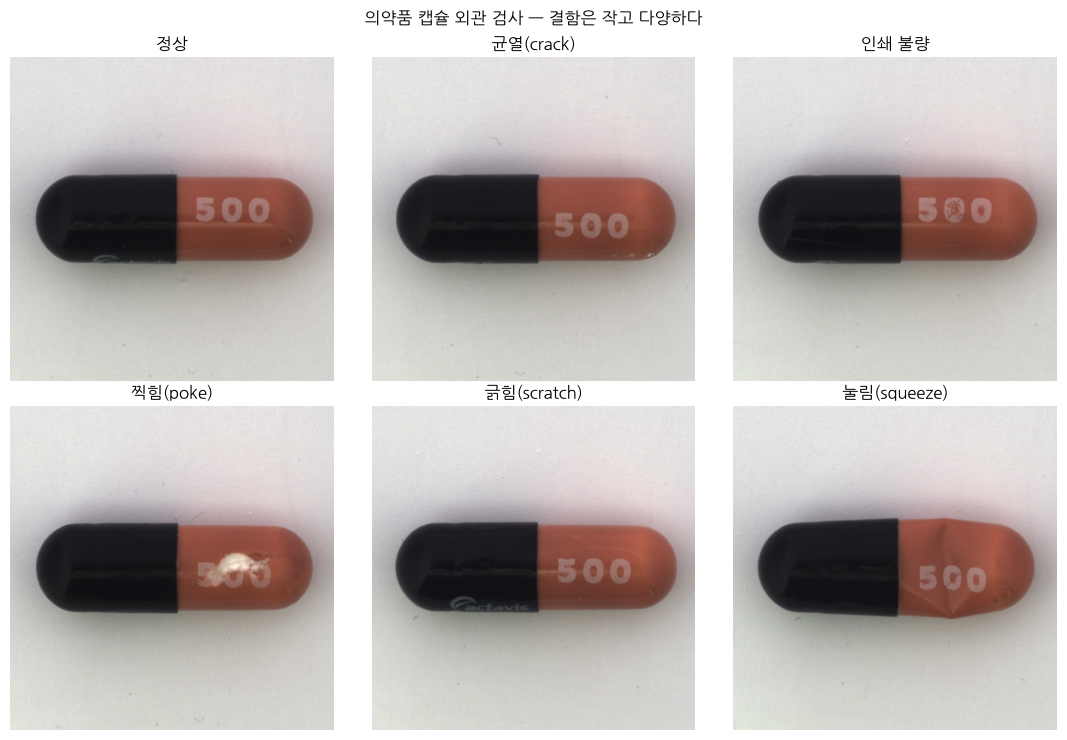

In [3]:
# 실제 이미지 보기 — 정상과 결함 5종
fig, ax = plt.subplots(2, 3, figsize=(11, 7.5))
names = {"good": "정상", "crack": "균열(crack)", "faulty_imprint": "인쇄 불량", "poke": "찍힘(poke)",
         "scratch": "긁힘(scratch)", "squeeze": "눌림(squeeze)"}
for a, (k, nm) in zip(ax.ravel(), names.items()):
    a.imshow(Image.open(test_dirs[k][0])); a.set_title(nm); a.axis("off")
plt.suptitle("의약품 캡슐 외관 검사 — 결함은 작고 다양하다", y=0.98); plt.tight_layout(); plt.show()

## 1. CNN 은 어떻게 '보는가' — 합성곱과 풀링
| 구성 | 역할 | 비유 |
|---|---|---|
| **합성곱(Convolution)** | 작은 필터를 이미지 위로 훑으며 **패턴(에지·질감)** 검출 | 돋보기로 훑어보기 |
| **활성화 함수(ReLU)** | 비선형성 부여 | "충분히 강한 신호만 통과" |
| **풀링(Pooling)** | 해상도를 줄여 **위치 변화에 둔감**하게 | 멀리서 보기 |
| **층을 쌓음** | 에지 → 질감 → 부품 → 물체로 **점점 추상화** | 단순 특징에서 의미로 |
| **전이학습** | 대규모 이미지로 학습된 가중치를 가져와 재사용 | 숙련된 검사원을 데려오기 |

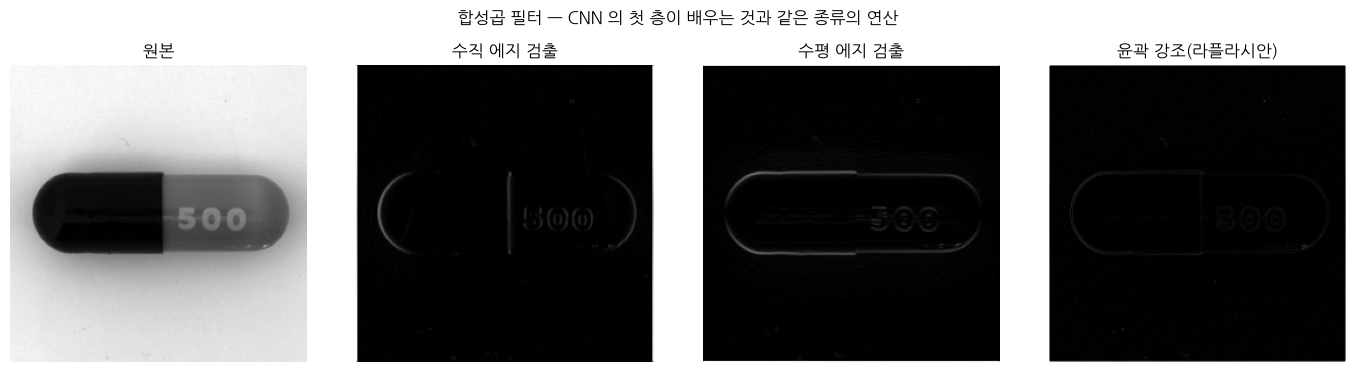

In [4]:
# 합성곱 필터가 실제로 무엇을 잡아내는지 직접 확인
img = Image.open(test_dirs["crack"][0]).convert("L").resize((256, 256))
x = torch.tensor(np.array(img), dtype=torch.float32)[None, None] / 255
kernels = {
    "원본": None,
    "수직 에지 검출": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "수평 에지 검출": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "윤곽 강조(라플라시안)": [[0, -1, 0], [-1, 4, -1], [0, -1, 0]],
}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, (name, k) in zip(ax, kernels.items()):
    out = np.array(img) if k is None else F.conv2d(x, torch.tensor(k, dtype=torch.float32)[None, None], padding=1)[0, 0].abs().numpy()
    a.imshow(out, cmap="gray"); a.set_title(name); a.axis("off")
plt.suptitle("합성곱 필터 — CNN 의 첫 층이 배우는 것과 같은 종류의 연산", y=1.02); plt.tight_layout(); plt.show()

## 2. ⭐ 제조 현장의 현실 — "결함 이미지가 없다"
신제품 라인을 세우면 **정상 제품 수백 장**은 바로 모이지만, **결함 샘플은 거의 없습니다.**
그래서 외관 검사 AI 는 보통 **정상만 학습하고, 정상에서 벗어난 정도를 점수화**합니다 (예제 06의 이상탐지와 같은 철학).

| 방식 | 필요한 데이터 | 장점 | 단점 |
|---|---|---|---|
| **지도학습 분류** | 정상 + 결함 **각각 수백 장** | 결함 유형까지 분류 | 결함 수집에 수개월 |
| **이상탐지 (이 노트북)** | **정상만** | 즉시 도입, 새로운 결함도 탐지 | 유형 분류는 못 함 |

In [5]:
# 사전학습 ResNet18 을 '특징 추출기'로 사용 (학습 없이 그대로 사용 = 전이학습)
weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights).to(device).eval()
feat_maps = {}
backbone.layer2.register_forward_hook(lambda m, i, o: feat_maps.__setitem__("l2", o))
backbone.layer3.register_forward_hook(lambda m, i, o: feat_maps.__setitem__("l3", o))
tf = transforms.Compose([transforms.Resize((256, 256)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def global_features(paths, bs=16):
    # 이미지 한 장 → 512차원 벡터 (전체 요약)
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i+bs]]).to(device)
        with torch.no_grad():
            h = backbone.avgpool(backbone.layer4(backbone.layer3(backbone.layer2(
                backbone.layer1(backbone.maxpool(backbone.relu(backbone.bn1(backbone.conv1(x))))))))).flatten(1)
        out.append(h.cpu().numpy())
    return np.vstack(out)

t = time.time()
F_train = global_features(train_paths)
test_paths = [p for v in test_dirs.values() for p in v]
y_true = np.array([0 if "/good/" in p else 1 for p in test_paths])
F_test = global_features(test_paths)
print(f"특징 추출 완료: 학습 {F_train.shape}, 시험 {F_test.shape} ({time.time()-t:.0f}초)")

특징 추출 완료: 학습 (219, 512), 시험 (132, 512) (22초)


In [6]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, RocCurveDisplay
nn_global = NearestNeighbors(n_neighbors=3).fit(F_train)
score_global = nn_global.kneighbors(F_test)[0].mean(1)          # 정상 이미지들과의 거리 = 이상 점수
auc_global = roc_auc_score(y_true, score_global)
print(f"① 전역 특징 기반 이상탐지 AUROC = {auc_global:.3f}")

① 전역 특징 기반 이상탐지 AUROC = 0.845


## 3. ⭐ 패치 기반 검사 — "어디가" 이상한지까지 찾기
이미지 전체를 벡터 하나로 요약하면 **작은 결함이 묻힙니다.** 캡슐 표면의 미세 균열은 이미지의 1%도 안 되니까요.
→ 이미지를 **격자(패치)** 로 나누고 **패치마다** 정상 여부를 판정합니다 (PatchCore 계열 방식).
- 장점: 작은 결함 탐지력↑, **결함 위치 히트맵** 자동 생성 → 검사원이 확인 가능 (설명가능성)

In [7]:
def patch_features(paths, bs=16):
    # 이미지 한 장 → (패치 수 × 특징차원): layer2·layer3 특징을 결합
    out = []
    for i in range(0, len(paths), bs):
        x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i+bs]]).to(device)
        with torch.no_grad(): backbone(x)
        a, b = feat_maps["l2"], feat_maps["l3"]
        a = F.avg_pool2d(a, 3, 1, 1); b = F.avg_pool2d(b, 3, 1, 1)
        b = F.interpolate(b, size=a.shape[-2:], mode="bilinear", align_corners=False)
        f = torch.cat([a, b], 1)                                   # (B, C, H, W)
        out.append(f.permute(0, 2, 3, 1).reshape(f.shape[0], -1, f.shape[1]).cpu().numpy())
    return np.concatenate(out)

t = time.time()
P_train = patch_features(train_paths)
grid = int(np.sqrt(P_train.shape[1]))
print(f"패치 격자: {grid}×{grid} = {P_train.shape[1]}개 패치, 각 {P_train.shape[2]}차원 ({time.time()-t:.0f}초)")

# 정상 패치 '기억 저장소(memory bank)' — 너무 크면 일부만 샘플링
bank = P_train.reshape(-1, P_train.shape[-1])
rng = np.random.RandomState(0)
bank = bank[rng.choice(len(bank), min(20000, len(bank)), replace=False)]
nn_patch = NearestNeighbors(n_neighbors=1).fit(bank)
print("정상 패치 저장소:", bank.shape)

패치 격자: 32×32 = 1024개 패치, 각 384차원 (14초)
정상 패치 저장소: (20000, 384)


In [8]:
t = time.time()
P_test = patch_features(test_paths)
d, _ = nn_patch.kneighbors(P_test.reshape(-1, P_test.shape[-1]))
dist_map = d.reshape(len(test_paths), grid, grid)        # 패치별 이상 거리
score_patch = dist_map.reshape(len(test_paths), -1).max(1)   # 이미지 점수 = 가장 이상한 패치
auc_patch = roc_auc_score(y_true, score_patch)
print(f"② 패치 기반 이상탐지 AUROC = {auc_patch:.3f}  (전역 방식 {auc_global:.3f})  [{time.time()-t:.0f}초]")

rows = []
gi = np.where(y_true == 0)[0]
for k, v in test_dirs.items():
    if k == "good": continue
    di = [i for i, p in enumerate(test_paths) if f"/{k}/" in p]
    rows.append({"결함 유형": names[k], "장수": len(di),
                 "전역 AUROC": roc_auc_score([0]*len(gi)+[1]*len(di), np.r_[score_global[gi], score_global[di]]),
                 "패치 AUROC": roc_auc_score([0]*len(gi)+[1]*len(di), np.r_[score_patch[gi], score_patch[di]])})
pd.DataFrame(rows).round(3)

② 패치 기반 이상탐지 AUROC = 0.944  (전역 방식 0.845)  [17초]


,결함 유형,장수,전역 AUROC,패치 AUROC
0,균열(crack),23,0.834,0.928
1,인쇄 불량,22,0.741,0.927
2,찍힘(poke),21,0.849,0.961
3,긁힘(scratch),23,0.822,0.915
4,눌림(squeeze),20,0.993,0.998


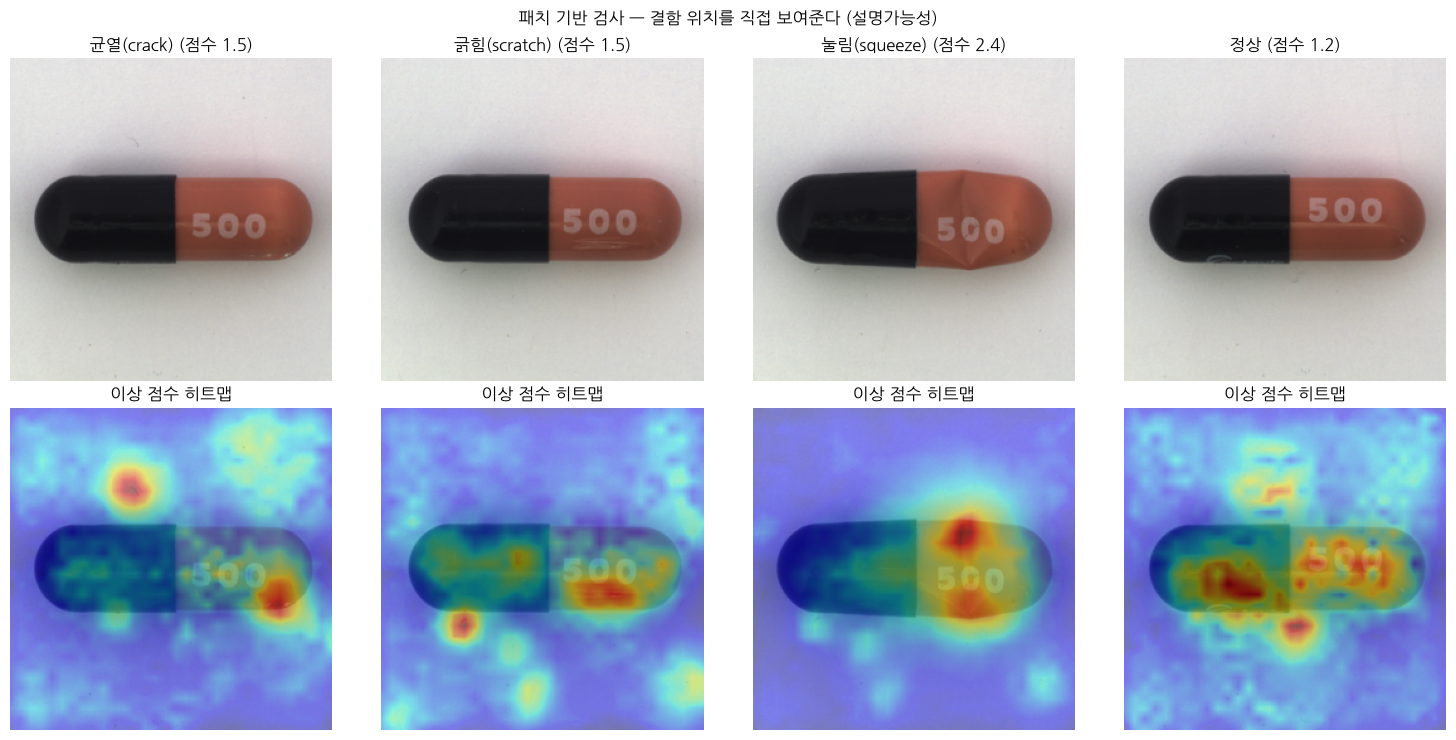

In [9]:
# ⭐ 결함 위치 히트맵 — 검사원에게 "여기가 이상합니다"를 보여준다
import scipy.ndimage as ndi
show = [("crack", 0), ("scratch", 1), ("squeeze", 0), ("good", 0)]
fig, ax = plt.subplots(2, 4, figsize=(15, 7.5))
for j, (k, idx) in enumerate(show):
    p = test_dirs[k][idx]; i = test_paths.index(p)
    img = Image.open(p).convert("RGB").resize((256, 256))
    hm = ndi.zoom(dist_map[i], 256 / grid, order=1)
    ax[0, j].imshow(img); ax[0, j].set_title(f"{names[k]} (점수 {score_patch[i]:.1f})"); ax[0, j].axis("off")
    ax[1, j].imshow(img); ax[1, j].imshow(hm, cmap="jet", alpha=0.45); ax[1, j].axis("off")
    ax[1, j].set_title("이상 점수 히트맵")
plt.suptitle("패치 기반 검사 — 결함 위치를 직접 보여준다 (설명가능성)", y=0.98); plt.tight_layout(); plt.show()

## 4. 검사 임계값 — 과검출(허위 불합격)과 미검출의 비용
외관 검사에서 임계값은 곧 **합격 기준**입니다.
- **미검출(결함을 합격)**: 불량품 출하 → 회수·환자 위험
- **과검출(정상을 불합격)**: 수율 손실, 재검사 인력, 폐기 비용

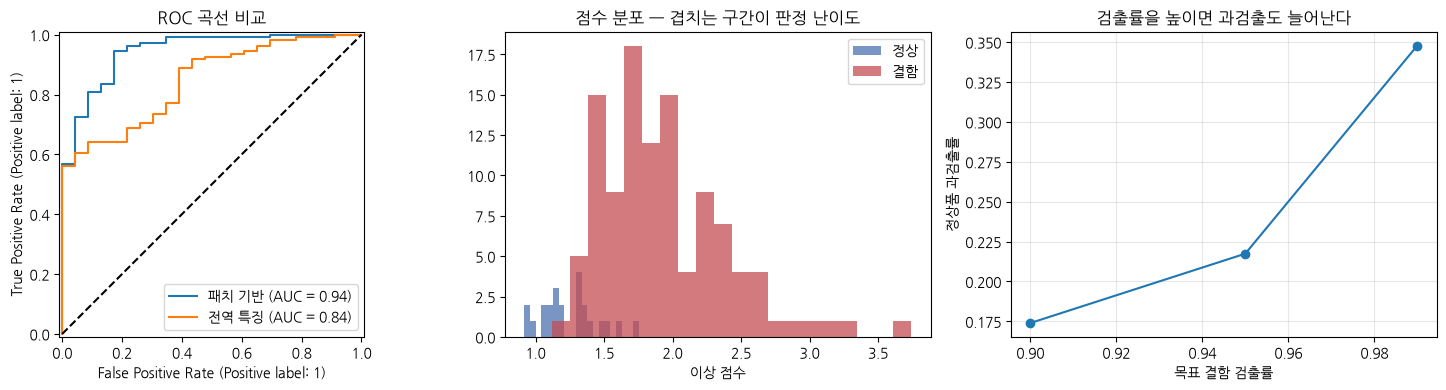

,목표 검출률,임계값,실제 검출률,과검출률(정상 불합격)
0,0.90,1.440,0.908,0.174
1,0.95,1.377,0.954,0.217
2,0.99,1.324,0.991,0.348


In [10]:
from sklearn.metrics import precision_recall_curve
prec, rec, ths = precision_recall_curve(y_true, score_patch)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_true, score_patch, ax=ax[0], name="패치 기반")
RocCurveDisplay.from_predictions(y_true, score_global, ax=ax[0], name="전역 특징")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC 곡선 비교")

ax[1].hist(score_patch[y_true == 0], bins=20, alpha=0.75, label="정상", color="#4C72B0")
ax[1].hist(score_patch[y_true == 1], bins=20, alpha=0.75, label="결함", color="#C44E52")
ax[1].set_xlabel("이상 점수"); ax[1].legend(); ax[1].set_title("점수 분포 — 겹치는 구간이 판정 난이도")

rows = []
for target_recall in [0.90, 0.95, 0.99]:
    i = np.where(rec[:-1] >= target_recall)[0]
    th = ths[i.max()] if len(i) else ths[0]
    pred = score_patch >= th
    rows.append({"목표 검출률": target_recall, "임계값": th,
                 "실제 검출률": (pred[y_true == 1]).mean(), "과검출률(정상 불합격)": (pred[y_true == 0]).mean()})
t_df = pd.DataFrame(rows)
ax[2].plot(t_df["목표 검출률"], t_df["과검출률(정상 불합격)"], "o-")
ax[2].set_xlabel("목표 결함 검출률"); ax[2].set_ylabel("정상품 과검출률"); ax[2].set_title("검출률을 높이면 과검출도 늘어난다"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
display(t_df.round(3))

> **현장 설계**: 보통 **AI 1차 선별 → 사람 2차 확인** 구조를 씁니다.
> AI 를 **검출률 99% 수준**으로 민감하게 두고(과검출 허용), 걸러진 것만 사람이 보면
> 전수 육안검사 대비 **검사 인력은 줄이고 미검출 위험은 낮출** 수 있습니다.

## 5. 지도학습 분류와 비교 — 결함 데이터가 모였다면
결함 이미지가 어느 정도 모이면 **결함 유형까지 분류**할 수 있습니다. (여기서는 특징 추출 + 로지스틱 회귀)

                precision    recall  f1-score   support

         crack      0.312     0.435     0.364        23
faulty_imprint      0.542     0.591     0.565        22
          good      0.565     0.565     0.565        23
          poke      0.556     0.476     0.513        21
       scratch      0.524     0.478     0.500        23
       squeeze      0.857     0.600     0.706        20

      accuracy                          0.523       132
     macro avg      0.559     0.524     0.535       132
  weighted avg      0.553     0.523     0.532       132



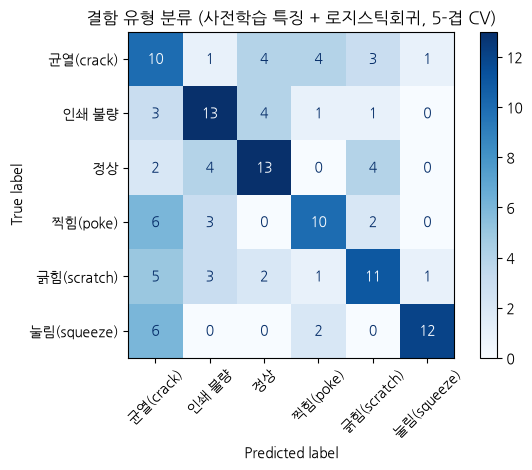

※ 유형별 20여 장뿐이라 성능이 제한적입니다. 실제 도입 시 유형당 수백 장이 필요합니다.


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

labels = np.array([os.path.basename(os.path.dirname(p)) for p in test_paths])
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0))
pred = cross_val_predict(clf, F_test, labels, cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(classification_report(labels, pred, digits=3))
ConfusionMatrixDisplay(confusion_matrix(labels, pred, labels=sorted(set(labels))),
                       display_labels=[names[k] for k in sorted(set(labels))]).plot(cmap="Blues", xticks_rotation=45)
plt.title("결함 유형 분류 (사전학습 특징 + 로지스틱회귀, 5-겹 CV)"); plt.tight_layout(); plt.show()
print("※ 유형별 20여 장뿐이라 성능이 제한적입니다. 실제 도입 시 유형당 수백 장이 필요합니다.")

## 6. 객체 검출(Object Detection) — 세는 문제와 위치 문제
외관 검사 외에 **개수 확인·위치 확인**이 필요하면 **객체 검출**(YOLO 계열)을 씁니다.
- 출력: 각 물체의 **경계상자(bounding box) + 클래스 + 확신도**
- 제약 현장: 블리스터 포장 정제 **개수 검사**, 바이알 라벨 위치, 공정 중 이물 검출

```python
# 학습 코드 골격 (GPU 권장)
from ultralytics import YOLO
model = YOLO("yolo11n.pt")                     # 사전학습 모델
model.train(data="pills.yaml", epochs=50, imgsz=640)   # 내 데이터로 미세조정
results = model("line_camera.jpg")             # 추론
```
`pills.yaml` 은 학습/검증 이미지 폴더와 클래스 이름을 적은 설정 파일이고,
라벨은 이미지마다 `클래스 x_center y_center width height`(0~1 정규화) 형식의 txt 로 준비합니다.

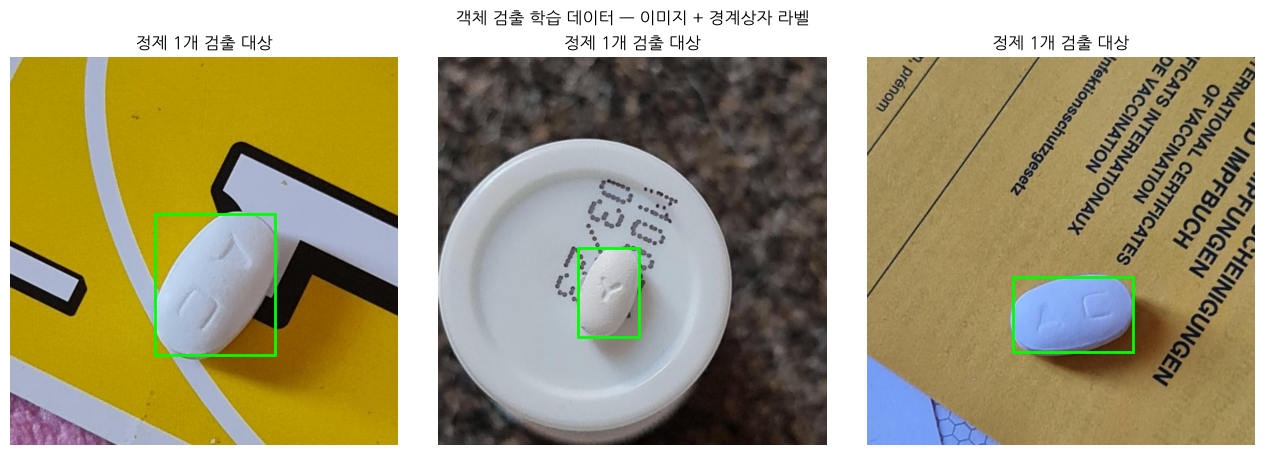

In [12]:
# 공개 정제(pill) 검출 데이터로 '라벨이 어떻게 생겼는지' 직접 확인
import io
try:
    url = "https://huggingface.co/api/datasets/Francesco/pills-sxdht/parquet/default/train/0.parquet"
    pills = pd.read_parquet(url)
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    for a, (_, r) in zip(ax, pills.head(3).iterrows()):
        im = Image.open(io.BytesIO(r["image"]["bytes"]))
        a.imshow(im); a.axis("off")
        for bb in r["objects"]["bbox"]:
            x, y, w, h = bb
            a.add_patch(plt.Rectangle((x, y), w, h, fill=False, color="lime", lw=2))
        a.set_title(f"정제 {len(r['objects']['bbox'])}개 검출 대상")
    plt.suptitle("객체 검출 학습 데이터 — 이미지 + 경계상자 라벨", y=1.0); plt.tight_layout(); plt.show()
except Exception as e:
    print("데이터 다운로드 실패(네트워크):", str(e)[:150])

## 7. GMP 환경에서 비전 검사 AI 를 쓰려면
| 항목 | 요구사항 |
|---|---|
| **설비 적격성** | 카메라·조명·렌즈 고정, IQ/OQ/PQ 수행. **조명이 바뀌면 모델 성능이 바뀝니다** |
| **모델 검증** | 알려진 결함 샘플(표준 불량품)로 검출률·과검출률 측정, 반복성 확인 |
| **변경 관리** | 모델 재학습·버전 업데이트는 **변경관리 절차** 대상 (예제 08) |
| **데이터 무결성** | 검사 이미지·판정 결과·모델 버전을 감사추적에 기록 (21 CFR Part 11) |
| **설명가능성** | 히트맵 등 **판정 근거 제시**, 최종 판정은 사람이 승인 |
| **성능 모니터링** | 과검출률 급증 = 조명/원자재 변화 신호 → 재학습 트리거 |

> ⚠️ **조명·배경이 학습 때와 달라지면 성능이 급락**합니다. 비전 검사 AI 실패의 1순위 원인입니다.

## 🧪 LLM 코딩 과제
```
patch_features(), nn_patch, dist_map, test_paths, y_true 가 있어.
이미지 점수를 '최댓값' 대신 '상위 1% 패치 평균'으로 바꿔서 AUROC 를 다시 계산하고,
최댓값 방식과 비교하는 표를 만들어줘. 어느 쪽이 작은 결함에 유리한지 설명도 덧붙여줘.
```

In [13]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| CNN | 합성곱으로 패턴 검출 → 층을 쌓아 추상화. **전이학습**으로 소량 데이터에서도 활용 |
| 정상만 학습 | 결함 데이터가 없는 현장의 현실적 해법 (이상탐지) |
| 패치 기반 | 작은 결함 탐지력↑ + **결함 위치 히트맵** → 검사원 확인·설명가능성 |
| 임계값 | 검출률과 과검출률의 거래. **AI 선별 + 사람 확인** 구조가 실용적 |
| GMP 요건 | 조명·설비 고정, 검증, 변경관리, 감사추적, 사람 최종 판정 |

➡️ **다음 예제 08**: 모델을 현장에 두고 **검증·감사추적·드리프트 관리** 하기